In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("taipei_population.csv")
df.head()

,統計期,人口增加數[人],自然增加/出生人數/總計[人],自然增加/出生人數/男[人],自然增加/出生人數/女[人],自然增加/粗出生率[千分比],自然增加/死亡人數/總計[人],自然增加/死亡人數/男[人],自然增加/死亡人數/女[人],自然增加/粗死亡率[千分比],...,社會增加/遷出人數/男[人],社會增加/遷出人數/女[人],社會增加/遷出率[千分比],社會增加/遷入人數[含同區住址變更][人],社會增加/遷出人數[含同區住址變更][人],社會增加/同區住址變更遷入人數[人],社會增加/同區住址變更遷出人數[人],社會增加數[人],社會增加率[千分比],人口總移動率[千分比]
0,57年,78976,40923,21191,19732,26.15,6471,3870,2601,4.13,...,108434,91321,127.63,244279,199755,0,0,44524,28.45,283.72
1,58年,107565,41667,21525,20142,25.30,6365,3843,2522,3.86,...,114676,100495,129.75,287434,215171,0,0,72263,43.58,303.08
2,59年,57460,45078,23257,21821,26.06,6574,4037,2537,3.80,...,132267,112276,140.47,263499,244543,0,0,18956,10.89,291.84
3,60年,70073,43542,22547,20995,24.13,6769,4144,2625,3.75,...,129578,115003,135.53,277881,244581,0,0,33300,18.45,289.52
4,61年,69426,42252,21700,20552,22.54,6869,4179,2690,3.66,...,143449,127788,144.71,305280,271237,0,0,34043,18.16,307.58


In [3]:
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei"]  # 微軟正黑體
plt.rcParams["axes.unicode_minus"] = False

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   統計期                    58 non-null     str    
 1   人口增加數[人]               58 non-null     int64  
 2   自然增加/出生人數/總計[人]        58 non-null     int64  
 3   自然增加/出生人數/男[人]         58 non-null     int64  
 4   自然增加/出生人數/女[人]         58 non-null     int64  
 5   自然增加/粗出生率[千分比]         58 non-null     float64
 6   自然增加/死亡人數/總計[人]        58 non-null     int64  
 7   自然增加/死亡人數/男[人]         58 non-null     int64  
 8   自然增加/死亡人數/女[人]         58 non-null     int64  
 9   自然增加/粗死亡率[千分比]         58 non-null     float64
 10  自然增加數[人]               58 non-null     int64  
 11  自然增加率[千分比]             58 non-null     float64
 12  社會增加/遷入人數/總計[人]        58 non-null     int64  
 13  社會增加/遷入人數/男[人]         58 non-null     int64  
 14  社會增加/遷入人數/女[人]         58 non-null     int64  
 15  社會增加/遷入率[千分比]      

In [5]:
data = df[[
    "統計期",
    "自然增加/出生人數/總計[人]",
    "自然增加/死亡人數/總計[人]",
    "自然增加數[人]",
    "社會增加/遷入人數/總計[人]",
    "社會增加/遷出人數/總計[人]",
    "社會增加數[人]"
]]

data.head()

,統計期,自然增加/出生人數/總計[人],自然增加/死亡人數/總計[人],自然增加數[人],社會增加/遷入人數/總計[人],社會增加/遷出人數/總計[人],社會增加數[人]
0,57年,40923,6471,34452,244279,199755,44524
1,58年,41667,6365,35302,287434,215171,72263
2,59年,45078,6574,38504,263499,244543,18956
3,60年,43542,6769,36773,277881,244581,33300
4,61年,42252,6869,35383,305280,271237,34043


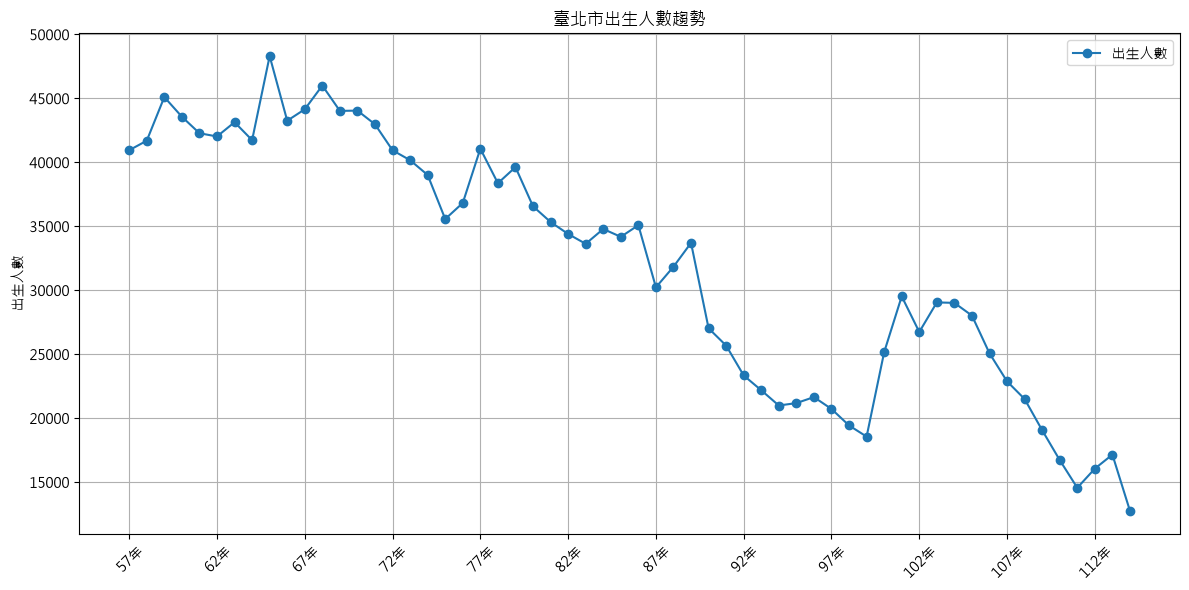

In [9]:
# 出生人數折線圖
plt.figure(figsize=(12,6))

plt.plot(
    data["統計期"],
    data["自然增加/出生人數/總計[人]"],
    marker="o",
    label="出生人數" 
)

plt.title("臺北市出生人數趨勢")
# plt.xlabel("統計期")
plt.ylabel("出生人數")
plt.xticks(rotation=45)

# 每 5 年顯示一次
plt.xticks(data.index[::5], data["統計期"][::5], rotation=45)

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()

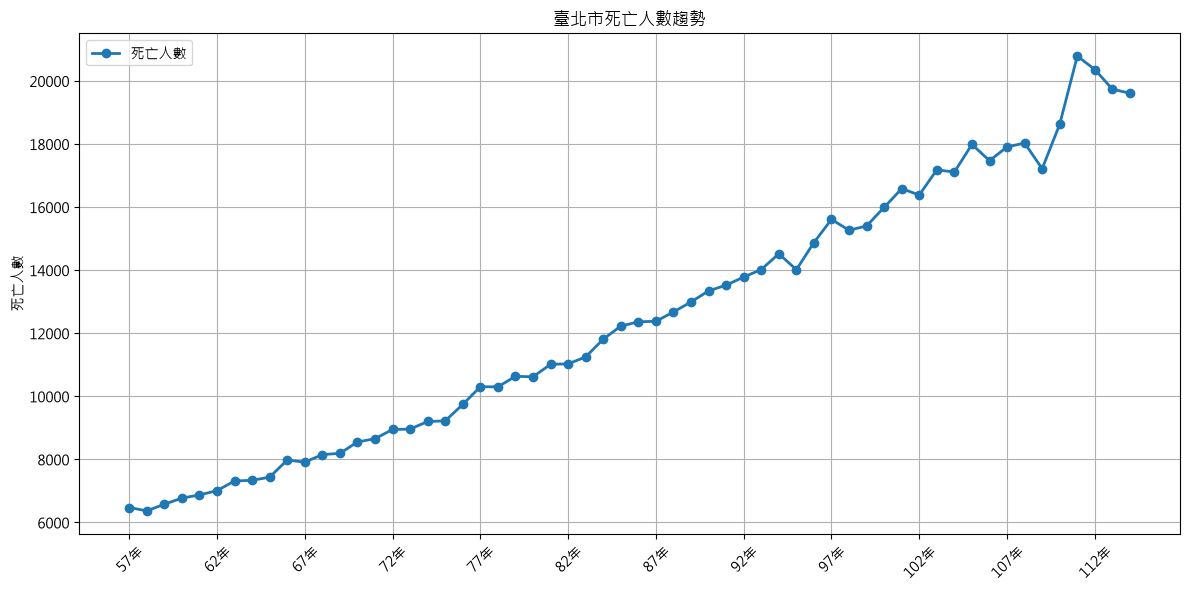

In [13]:
# 死亡人數折線圖
plt.figure(figsize=(12,6))

plt.plot(
    data["統計期"],
    data["自然增加/死亡人數/總計[人]"],
    marker="o",
    linewidth=2,
    label="死亡人數"
)

plt.title("臺北市死亡人數趨勢")
# plt.xlabel("統計期")
plt.ylabel("死亡人數")

# 每 5 年顯示一次（可依需要改成 10）
plt.xticks(data.index[::5], data["統計期"][::5], rotation=45)

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()

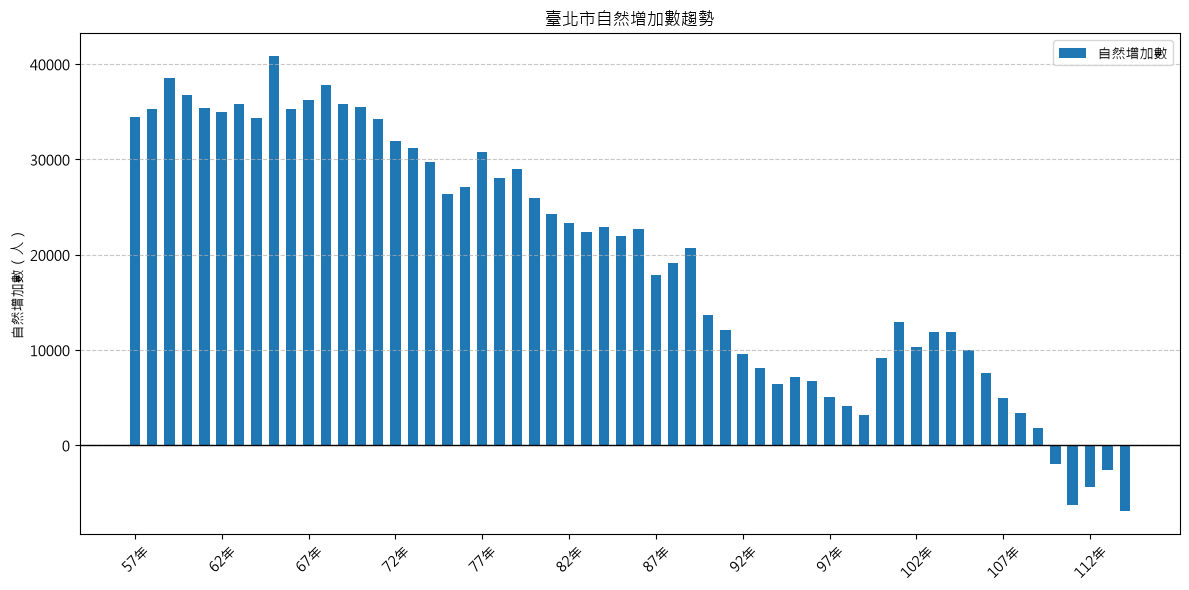

In [14]:
# 自然增加數長條圖
plt.figure(figsize=(12,6))

plt.bar(
    data["統計期"],
    data["自然增加數[人]"],
    width=0.6,
    label="自然增加數"
)

# 0 基準線
plt.axhline(y=0, color="black", linewidth=1)

plt.title("臺北市自然增加數趨勢")
# plt.xlabel("統計期")
plt.ylabel("自然增加數（人）")

# 每 5 年顯示一次
plt.xticks(data.index[::5], data["統計期"][::5], rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.legend()

plt.tight_layout()

plt.show()

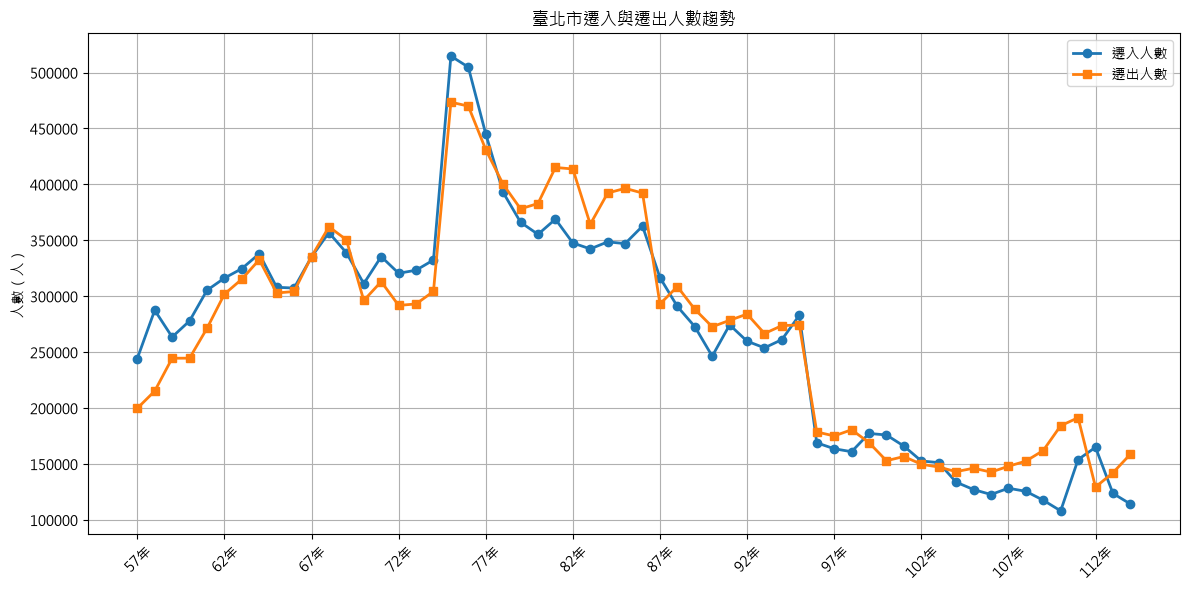

In [15]:
plt.figure(figsize=(12,6))

plt.plot(
    data["統計期"],
    data["社會增加/遷入人數/總計[人]"],
    marker="o",
    linewidth=2,
    label="遷入人數"
)

plt.plot(
    data["統計期"],
    data["社會增加/遷出人數/總計[人]"],
    marker="s",
    linewidth=2,
    label="遷出人數"
)

plt.title("臺北市遷入與遷出人數趨勢")
# plt.xlabel("統計期")
plt.ylabel("人數（人）")
plt.xticks(data.index[::5], data["統計期"][::5], rotation=45)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

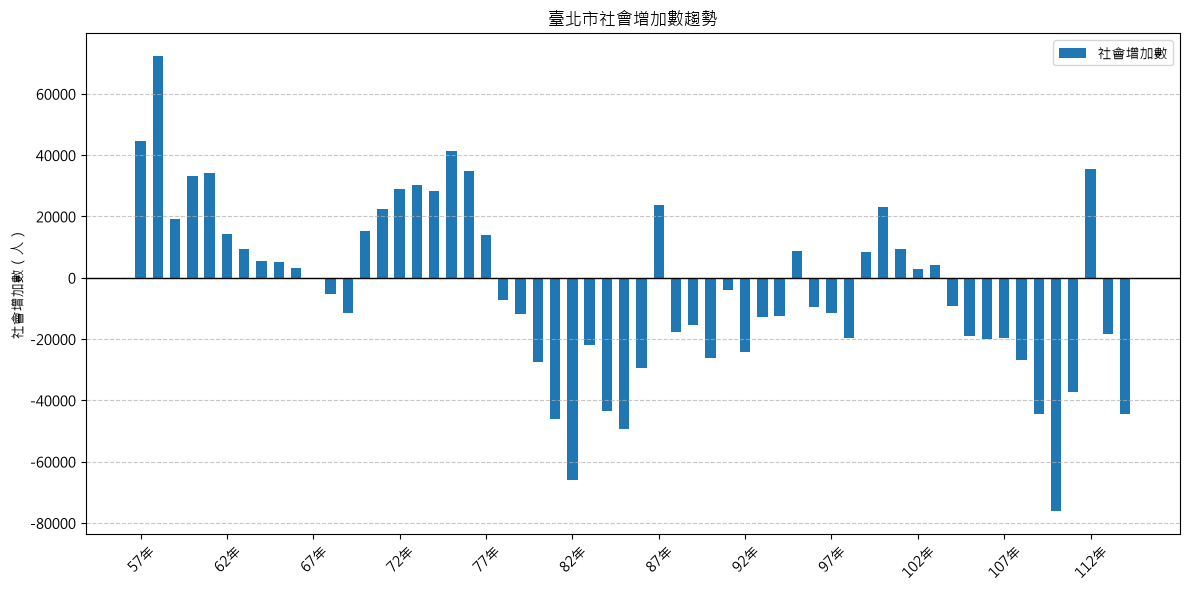

In [16]:
# 社會增加數長條圖
plt.figure(figsize=(12,6))

plt.bar(
    data["統計期"],
    data["社會增加數[人]"],
    width=0.6,
    label="社會增加數"
)

# 0 基準線
plt.axhline(y=0, color="black", linewidth=1)

plt.title("臺北市社會增加數趨勢")
# plt.xlabel("統計期")
plt.ylabel("社會增加數（人）")

# 每5年顯示一次
plt.xticks(data.index[::5], data["統計期"][::5], rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.legend()
plt.tight_layout()

plt.show()

In [17]:
print(data["統計期"].tail())

53    110年
54    111年
55    112年
56    113年
57    114年
Name: 統計期, dtype: str
